In [15]:
import geopandas as gpd
import glob
import pandas as pd

pa = gpd.read_file('capas/DOTACI_Sym_PtosAgua.shp')
masas_files = glob.glob('capas/Masas*.shp')
masas = pd.concat([gpd.read_file(x) for x in masas_files])

In [16]:
pa = pa[pa.intersects(masas.dissolve().iloc[0].geometry.buffer(500))]

In [18]:
pa.to_file('capas/puntos_agua.gpkg')

In [1]:
import geopandas as gpd

o = gpd.read_file('BRUTOS/VEGETACION/OCUPAC_Pol_MCA_VE2023.shp')
m = gpd.read_file('BRUTOS/CONCEJOS/DIADMI_Pol_Concejo.shp')
r = m[m.CONCEJO == 'Rocaforte']

In [3]:
o = o[o.intersects(r.iloc[0].geometry)]

In [4]:
o['geometry'] = o.intersection(r.iloc[0].geometry)

In [7]:
o = o.explode()

In [9]:
o = o[o.geometry.type == 'Polygon']

In [10]:
o.geometry.type.unique()

array(['Polygon'], dtype=object)

In [12]:
o.to_file('BRUTOS/VEGETACION/ocupacion_Rocaforte.gpkg')

<Axes: >

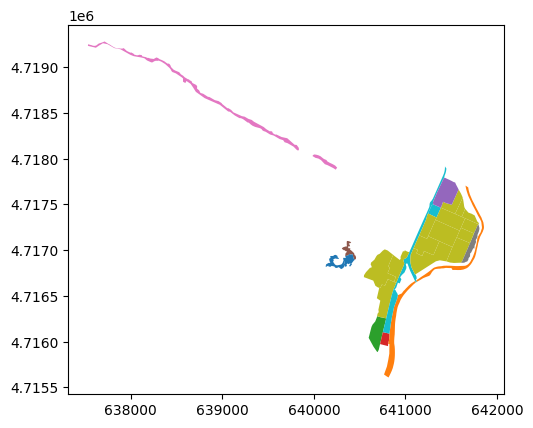

In [15]:
o[o.GRUPO == 'Improductivo'].plot(column='COBERTURAP')

In [1]:
import geopandas as gpd

e = gpd.read_file('BRUTOS/EDIFICIOS/edificios_rocaforte.gpkg')
m = gpd.read_file('./capas/Masas_Rocaforte_v2.shp')

In [7]:
peg = m[m.intersects(e.dissolve().iloc[0].geometry.buffer(30))]
peg['geometry'] = peg.intersection(e.dissolve().iloc[0].geometry.buffer(30))

/home/nano/anaconda3/envs/pdal/lib/python3.12/site-packages/geopandas/geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [10]:
faja = gpd.read_file('temp/faja_auxiliar_rocaforte.gpkg')

In [13]:
faja

,geometry
0,"MULTILINESTRING ((637534.508 4719235.019, 6375..."


In [20]:
peg_cumbrera = m[m.intersects(faja.iloc[0].geometry.buffer(20))]
peg_cumbrera.loc[:, 'geometry'] = peg_cumbrera.intersection(faja.iloc[0].geometry.buffer(20))

In [24]:
peg_ant = gpd.read_file('PEG/propuesta_PEG.gpkg')

In [30]:
peg_ant.merge(peg.dissolve(), on='geometry', how='left')

,id,observaciones,tipo,vegetacion,geometry,DCodMun_12,DPoligon_2,DParcela_2,propieda_4,Shape_Ar_2,Parcelas
0,1.0,Si el fuego llega a este punto en condiciones ...,"Punto crítico, cabecera de barranco",Pino carrasco y matorral mediteráneo,"MULTIPOLYGON (((643017.971 4716734.998, 642973...",NaN,NaN,NaN,NaN,NaN,NaN
1,2.0,El fuego cuando llegue a esta zona cambiará de...,Punto de oportunidad,Ladera sur pino carrasco y matorral mediteráne...,"MULTIPOLYGON (((643853.937 4717140.994, 643663...",NaN,NaN,NaN,NaN,NaN,NaN
2,3.0,Con el objetivo de mejorar la defensa de biene...,Defensivo,Pino carraso,"MULTIPOLYGON (((641068.44 4715835.076, 641077....",NaN,NaN,NaN,NaN,NaN,NaN
3,5.0,El fuego cuando llegue a esta zona cambiará de...,Defensivo,Masa de Quejigo,"MULTIPOLYGON (((635361.497 4720306.309, 635422...",NaN,NaN,NaN,NaN,NaN,NaN
4,6.0,El fuego si llega a este punto tiene potencial...,"Punto crítico, nudo de barranco",Masa de quejigo,"MULTIPOLYGON (((633353.923 4719238.8, 633321.6...",NaN,NaN,NaN,NaN,NaN,NaN
5,7.0,El fuego cuando llegue a esta zona cambiará de...,Punto de oportunidad,Pino laricio,"MULTIPOLYGON (((631922.42 4719944.105, 632009....",NaN,NaN,NaN,NaN,NaN,NaN
6,8.0,Se propone seguir manteniendo baja carga de co...,"Punto crítico, cabecera de barranco","Forestal no arbolado, con quejigos aislados","MULTIPOLYGON (((632942.323 4719582.189, 632971...",NaN,NaN,NaN,NaN,NaN,NaN
7,4.0,Con el objetivo de mejorar la defensa de biene...,Defensivo,Pino carrasco,"MULTIPOLYGON (((639485.479 4711280.801, 639486...",NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
import pandas as pd

p1 = pd.concat([peg_ant, peg.dissolve()])[peg_ant.columns]

In [35]:
p2 = pd.concat([p1, peg_cumbrera.dissolve()])[p1.columns]

In [37]:
p2.to_file('PEG/propuesta_PEG_v2.gpkg')

In [4]:
import geopandas as gpd

sang = gpd.read_file('temp/sanguesa_recortado.gpkg')

In [5]:
l = gpd.read_file('BRUTOS/LIDAR/CUADRICULAS/lida3_navarra.gpkg')

In [6]:
j = l[l.intersects(sang.iloc[0].geometry)]

In [7]:
import glob

a = glob.glob('../Descargas/PNOA_2024*')

In [8]:
k = j[j.nombre.str.endswith('NPC03.laz')]

In [9]:
f = [x.split('/')[-1] for x in a]

In [10]:
fi = [x.replace('_', '-') for x in f]

In [12]:
k[k.nombre.isin(fi)]

,num,nombre,formato,anho,densidad,tamanho,coord_x,coord_y,ORIG_SRID,geometry
9648,12617012,PNOA-2024-NAV-644-4718-H30-NPC03.laz,LAZ,2024,5 ptos/m2,73.44,644000,4718000,25830,"POLYGON ((645000 4717000, 645000 4718000, 6440..."


In [13]:
import glob

a = glob.glob('BRUTOS/LIDAR/SANGUESA/PNOA_2024*')

In [14]:
k = j[j.nombre.str.endswith('NPC03.laz')]

In [15]:
f = [x.split('/')[-1] for x in a]

In [16]:
fi = [x.replace('_', '-') for x in f]

In [17]:
k[~k.nombre.isin(fi)]

,num,nombre,formato,anho,densidad,tamanho,coord_x,coord_y,ORIG_SRID,geometry
9406,12610596,PNOA-2024-NAV-640-4708-H30-NPC03.laz,LAZ,2024,5 ptos/m2,131.75,640000,4708000,25830,"POLYGON ((641000 4707000, 641000 4708000, 6400..."
9648,12617012,PNOA-2024-NAV-644-4718-H30-NPC03.laz,LAZ,2024,5 ptos/m2,73.44,644000,4718000,25830,"POLYGON ((645000 4717000, 645000 4718000, 6440..."
